# 问题 1：影响力网络

用 `influence_data` 建立 influencer → follower 的有向网络，定义「音乐影响力」指标，抽一个子网络描述。

**指标设计（均用 `scipy.sparse` 手写，不依赖 networkx）：**
- 出度：被记录影响的追随者数量（直接影响）
- 入度：被记录的影响来源数量
- 反向 PageRank：源头影响力（谁把影响传播给更多后续节点）
- 三度影响力：3 跳内能触达的艺术家数
- 跨流派多样性 DIG：直接追随者涉及的不同流派数

In [1]:
import pandas as pd
import numpy as np
import scipy.sparse as sp
from scipy.sparse import csgraph
import matplotlib.pyplot as plt

plt.rcParams['figure.dpi'] = 100

edges = pd.read_csv('output/edges.csv', dtype=str)
artists = pd.read_csv('output/artists.csv', dtype=str)

print('edges:', edges.shape, '| artists:', artists.shape)

edges: (42770, 8) | artists: (5854, 18)


## 1. 建图与基本结构

In [2]:
# 节点：所有出现在边中的艺术家
all_ids = np.unique(np.concatenate([edges['influencer_id'].values, edges['follower_id'].values]))
node2idx = {n: i for i, n in enumerate(all_ids)}
n = len(all_ids)

row = edges['influencer_id'].map(node2idx).values
col = edges['follower_id'].map(node2idx).values
data = np.ones(len(edges))
A = sp.csr_matrix((data, (row, col)), shape=(n, n))  # A[i,j]=1 表示 i 影响 j

m = A.nnz
density = m / (n * (n - 1))
bidir = (A.multiply(A.T)).nnz // 2  # 双向边（2-环）数量
n_comp, labels = csgraph.connected_components(A + A.T, directed=False)

print(f'节点数 n = {n}')
print(f'边数 m = {m}')
print(f'密度 = {density:.5f}')
print(f'平均度 = {m/n:.3f}')
print(f'双向边(2-环) = {bidir}  → 网络并非无环')
print(f'无向连通分量数 = {n_comp}')
print(f'最大连通分量大小 = {np.bincount(labels).max()} / {n}')

节点数 n = 5603
边数 m = 42770
密度 = 0.00136
平均度 = 7.633
双向边(2-环) = 39  → 网络并非无环
无向连通分量数 = 3
最大连通分量大小 = 5599 / 5603


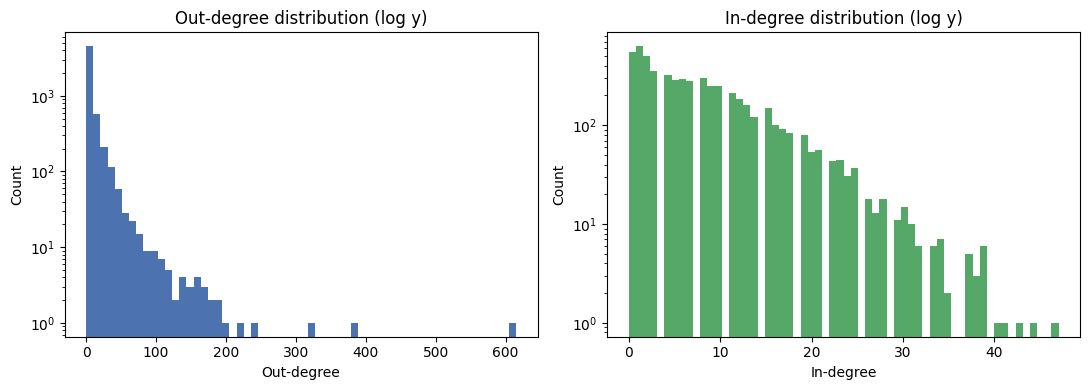

In [3]:
outdeg = np.asarray(A.sum(axis=1)).ravel()  # 出度
indeg = np.asarray(A.sum(axis=0)).ravel()  # 入度

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(outdeg, bins=60, color='#4C72B0')
axes[0].set_xlabel('Out-degree'); axes[0].set_ylabel('Count')
axes[0].set_title('Out-degree distribution (log y)')
axes[0].set_yscale('log')
axes[1].hist(indeg, bins=60, color='#55A868')
axes[1].set_xlabel('In-degree'); axes[1].set_ylabel('Count')
axes[1].set_title('In-degree distribution (log y)')
axes[1].set_yscale('log')
plt.tight_layout(); plt.show()

## 2. 影响力指标

In [4]:
def pagerank(A, alpha=0.85, tol=1e-8, max_iter=200):
    """幂迭代 PageRank。A[i,j]=1 表示 i→j；返回的 r[j] 高表示影响流入 j 多。"""
    n = A.shape[0]
    outdeg = np.asarray(A.sum(axis=1)).ravel().astype(float)
    outdeg[outdeg == 0] = 1.0
    M = A.transpose().tocsr() @ sp.diags(1.0 / outdeg)  # M[j,i] = A[i,j]/outdeg(i)
    r = np.full(n, 1.0 / n)
    for _ in range(max_iter):
        r_new = alpha * (M @ r) + (1 - alpha) / n
        if np.abs(r_new - r).sum() < tol:
            return r_new
        r = r_new
    return r

def reach_within_k(A, k=3):
    """每个节点 k 跳内能触达的不同节点数。"""
    Ai = A.astype(bool).astype(np.int8)
    cur = Ai.copy(); reach = Ai.copy()
    for _ in range(k - 1):
        cur = (cur @ Ai).astype(bool).astype(np.int8)
        reach = reach + cur
    reach = reach.astype(bool)
    return np.asarray(reach.sum(axis=1)).ravel()

# 源头影响力 = 在反向图 A.T 上跑 PageRank（被更多后续节点“指向”的节点 = 源头）
pr_source = pagerank(A.T)
# 被影响力 = 在原图 A 上跑 PageRank
pr_sink   = pagerank(A)
reach3    = reach_within_k(A, 3)

# 跨流派多样性（直接 follower 的不同流派数）
dig = edges.groupby('influencer_id')['follower_main_genre'].nunique()

# 组装成 DataFrame
df = pd.DataFrame({
    'out_degree': outdeg,
    'in_degree': indeg,
    'pagerank_source': pr_source,
    'pagerank_sink': pr_sink,
    'reach3': reach3,
}, index=all_ids)
df.index.name = 'artist_id'
df['DIG'] = df.index.map(dig).fillna(0)

name_map = artists.set_index('artist_id')['artist_name']
genre_map = artists.set_index('artist_id')['genre']
df['artist_name'] = df.index.map(name_map)
df['genre'] = df.index.map(genre_map)

print('影响力指标计算完成，共', len(df), '个节点')

影响力指标计算完成，共 5603 个节点


## 3. 影响力排名（按源头 PageRank）

In [5]:
def show_top(by, k=15):
    return (df.sort_values(by, ascending=False)
            .head(k)[['artist_name', 'genre', 'out_degree', 'in_degree', 'reach3', 'DIG', by]]
            .reset_index(drop=True))

print('=== Top 15 源头影响力（反向 PageRank）===')
show_top('pagerank_source')

=== Top 15 源头影响力（反向 PageRank）===


,artist_name,genre,out_degree,in_degree,reach3,DIG,pagerank_source
0,Cab Calloway,Jazz,27.0,0.0,2596,8.0,0.011837
1,Billie Holiday,Vocal,106.0,2.0,3570,9.0,0.011232
2,Lester Young,Jazz,51.0,1.0,2757,4.0,0.009664
3,Louis Jordan,Jazz,53.0,2.0,3678,9.0,0.007731
4,T-Bone Walker,Blues,48.0,2.0,3343,4.0,0.005677
5,Sister Rosetta Tharpe,Religious,13.0,3.0,2557,5.0,0.005292
6,The Beatles,Pop/Rock,615.0,31.0,3759,15.0,0.005173
7,The Mills Brothers,Vocal,35.0,1.0,3226,6.0,0.004414
8,Roy Acuff,Country,50.0,0.0,2514,3.0,0.003918
9,Mississippi Fred McDowell,Blues,17.0,0.0,2030,3.0,0.003904


In [6]:
print('=== Top 15 出度（直接影响的追随者数）===')
show_top('out_degree')

=== Top 15 出度（直接影响的追随者数）===


,artist_name,genre,out_degree,in_degree,reach3,DIG,out_degree
0,The Beatles,Pop/Rock,615.0,31.0,3759,15.0,615.0
1,Bob Dylan,Pop/Rock,389.0,29.0,3830,8.0,389.0
2,The Rolling Stones,Pop/Rock,319.0,39.0,3279,7.0,319.0
3,David Bowie,Pop/Rock,238.0,25.0,2261,6.0,238.0
4,Led Zeppelin,Pop/Rock,221.0,24.0,2151,6.0,221.0
5,Jimi Hendrix,Pop/Rock,201.0,32.0,3610,10.0,201.0
6,The Kinks,Pop/Rock,192.0,8.0,2785,1.0,192.0
7,The Beach Boys,Pop/Rock,186.0,13.0,2970,5.0,186.0
8,Hank Williams,Country,184.0,3.0,3442,6.0,184.0
9,The Velvet Underground,Pop/Rock,181.0,8.0,2303,4.0,181.0


## 4. 子网络：以 Blues 为例

抽取 Blues 流派内影响力最高的若干节点及其边，画有向子图。布局用谱嵌入（`spectral_embedding`）。

d:\Anaconda\envs\dev\Lib\site-packages\sklearn\manifold\_spectral_embedding.py:329: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(
C:\Users\SHEN\AppData\Local\Temp\ipykernel_42164\3388364844.py:37: UserWarning: Glyph 23376 (\N{CJK UNIFIED IDEOGRAPH-5B50}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\SHEN\AppData\Local\Temp\ipykernel_42164\3388364844.py:37: UserWarning: Glyph 32593 (\N{CJK UNIFIED IDEOGRAPH-7F51}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\SHEN\AppData\Local\Temp\ipykernel_42164\3388364844.py:37: UserWarning: Glyph 32476 (\N{CJK UNIFIED IDEOGRAPH-7EDC}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\SHEN\AppData\Local\Temp\ipykernel_42164\3388364844.py:37: UserWarning: Glyph 65288 (\N{FULLWIDTH LEFT PARENTHESIS}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\SHEN\AppData\Local\Temp\ipykernel_

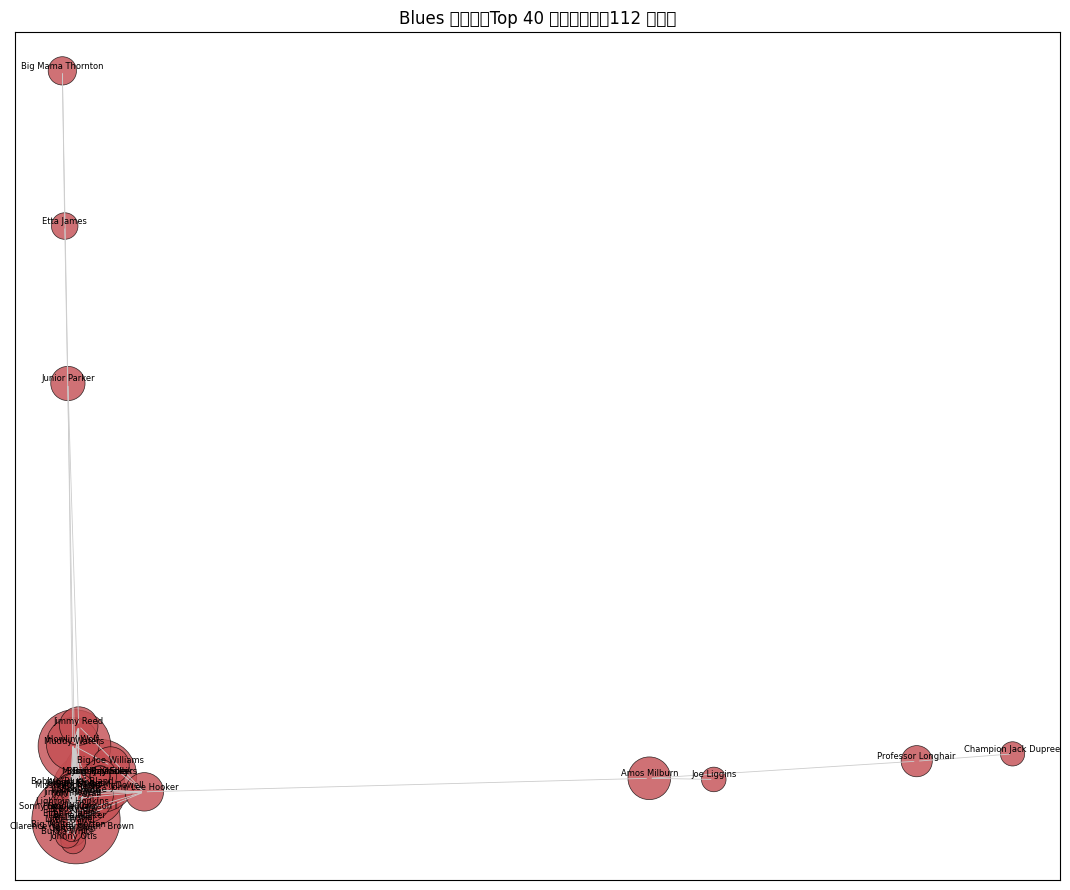

In [7]:
from sklearn.manifold import spectral_embedding

# 选 Blues 流派的节点，取影响力 top K
blues_nodes = df[df['genre'] == 'Blues']
K = 40
sub_ids = blues_nodes.sort_values('pagerank_source', ascending=False).head(K).index
sub_set = set(sub_ids)

# 子图：这些节点之间的边
mask = edges['influencer_id'].isin(sub_set) & edges['follower_id'].isin(sub_set)
sub_edges = edges[mask]

sub_idx = {nid: i for i, nid in enumerate(sub_ids)}
srow = sub_edges['influencer_id'].map(sub_idx).values
scol = sub_edges['follower_id'].map(sub_idx).values
A_sub = sp.csr_matrix((np.ones(len(sub_edges)), (srow, scol)), shape=(K, K))

# 谱嵌入布局
pos = spectral_embedding(A_sub + A_sub.T, n_components=2, random_state=0)

fig, ax = plt.subplots(figsize=(11, 9))
for u, v in zip(srow, scol):
    ax.annotate('', xy=pos[v], xytext=pos[u],
                arrowprops=dict(arrowstyle='-', color='#cccccc', lw=0.6))

# 节点大小按源头影响力
sizes = 40 + 4000 * (df.loc[sub_ids, 'pagerank_source'].values /
                     df.loc[sub_ids, 'pagerank_source'].values.max())
ax.scatter(pos[:, 0], pos[:, 1], s=sizes, c='#C44E52', alpha=0.8, edgecolors='black', lw=0.5)

for i, nid in enumerate(sub_ids):
    name = name_map.get(nid, nid)
    ax.text(pos[i, 0], pos[i, 1], name, fontsize=6, ha='center', va='bottom')

ax.set_title(f'Blues 子网络（Top {K} 影响力节点，{len(sub_edges)} 条边）')
ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

## 5. 解读要点

- **网络非无环**：存在双向边（互有影响），解释指标时不能当作 DAG。
- **重尾度分布**：少数艺术家影响大量追随者，多数艺术家影响很少人——符合「明星效应」。
- **源头 PageRank vs 出度**：源头 PageRank 进一步考虑了「影响的影响」（间接传播），Top 榜应更偏「奠基型」艺术家。
- **DIG 高**：表示影响力跨多个流派，是「跨界桥梁」型艺术家。